# ClickHouse — практика МГТУ Баумана

**Кластер:** 2 шарда × 2 реплики

**Что делаем:**
1. Подключаемся к кластеру
2. Смотрим устройство кластера
3. Создаём таблицы (локальные + Distributed)
4. Вставляем данные и смотрим как они распределяются
5. Исследуем MergeTree — Parts, сжатие, индексы
6. Пишем аналитические запросы
7. Создаём MaterializedView
8. Смотрим system таблицы


## 0. Установка зависимостей

In [5]:
pip install clickhouse-connect pandas matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
  Using cached matplotlib-3.9.4-cp39-cp39-macosx_11_0_arm64.whl.metadata (11 kB)
  Using cached contourpy-1.3.0-cp39-cp39-macosx_11_0_arm64.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.60.2-cp39-cp39-macosx_10_9_universal2.whl.metadata (113 kB)
  Using cached kiwisolver-1.4.7-cp39-cp39-macosx_11_0_arm64.whl.metadata (6.3 kB)
  Using cached pillow-11.3.0-cp39-cp39-macosx_11_0_arm64.whl.metadata (9.0 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl.metadata (3.9 kB)
Using cached matplotlib-3.9.4-cp39-cp39-macosx_11_0_arm64.whl (7.8 MB)
Using cached contourpy-1.3.0-cp39-cp39-macosx_11_0_arm64.whl (249 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.60.2-cp39-cp39-macosx_10_9_universal2.whl (2.9 MB)
Using cached importlib_resources-6.5

In [41]:
import clickhouse_connect
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import random
import time

# Подключаемся к первой ноде кластера (shard1/replica1)
client = clickhouse_connect.get_client(
    host='localhost',
    port=8123,
    username='default',
    password=''
)

# Проверяем подключение
result = client.query('SELECT version()')
print(f'ClickHouse version: {result.first_row[0]}')

ClickHouse version: 24.3.18.7


## 1. Исследуем кластер

Смотрим что за кластер у нас поднят

In [42]:
# Смотрим все шарды и реплики кластера
df = client.query_df("""
SELECT
    cluster,
    shard_num,
    replica_num,
    host_name,
    port,
    is_local
FROM system.clusters
WHERE cluster = 'dwh_cluster'
ORDER BY shard_num, replica_num
""")
print(df.to_string(index=False))

    cluster  shard_num  replica_num       host_name  port  is_local
dwh_cluster          1            1 clickhouse-s1r1  9000         1
dwh_cluster          1            2 clickhouse-s1r2  9000         0
dwh_cluster          2            1 clickhouse-s2r1  9000         0
dwh_cluster          2            2 clickhouse-s2r2  9000         0


In [43]:
# Смотрим макросы текущей ноды
df = client.query_df("""
SELECT macro, substitution
FROM system.macros
""")
print("Макросы текущей ноды:")
print(df.to_string(index=False))

Макросы текущей ноды:
  macro    substitution
cluster     dwh_cluster
replica clickhouse-s1r1
  shard               1


In [47]:
df = client.query_df("""
SELECT *
FROM clusterAllReplicas('dwh_cluster', system.tables)
""")
print("Все таблицы:")
print(df.to_string(index=False))

Все таблицы:


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [ ]:
SELECT hostName() AS host, version() AS version

In [48]:
# Смотрим все ноды кластера и их hostname
df = client.query_df("""
SELECT *
FROM clusterAllReplicas('dwh_cluster', system.one)
""")
print("Все ноды кластера:")
print(df.to_string(index=False))

Все ноды кластера:
 dummy
     0
     0
     0
     0


## 2. Создаём таблицы

Паттерн в ClickHouse:
- **Локальная таблица** (ReplicatedMergeTree) — реальные данные, на каждой ноде своя
- **Distributed таблица** — виртуальная, роутер запросов по всем шардам

In [13]:
# Создаём базу данных на всём кластере
client.command("""
CREATE DATABASE IF NOT EXISTS dwh ON CLUSTER dwh_cluster
""")
print("База данных dwh создана")

База данных dwh создана


In [14]:
# Создаём локальную таблицу на всех нодах
# {shard} и {replica} заменяются из macros.xml каждой ноды
client.command("""
CREATE TABLE IF NOT EXISTS dwh.events_local ON CLUSTER dwh_cluster
(
    event_date      Date,
    event_time      DateTime,
    user_id         UInt64,
    event_type      LowCardinality(String),
    platform        LowCardinality(String),
    country         LowCardinality(String),
    value           Float64,
    session_id      String
)
ENGINE = ReplicatedMergeTree(
    '/clickhouse/tables/{shard}/dwh/events_local',
    '{replica}'
)
PARTITION BY toYYYYMM(event_date)
ORDER BY (event_type, user_id, event_time)
""")
print("Локальная таблица events_local создана на всех нодах")

Локальная таблица events_local создана на всех нодах


In [15]:
# Создаём Distributed таблицу — точка входа для запросов
client.command("""
CREATE TABLE IF NOT EXISTS dwh.events ON CLUSTER dwh_cluster
AS dwh.events_local
ENGINE = Distributed(
    'dwh_cluster',      -- кластер
    'dwh',              -- база данных
    'events_local',     -- локальная таблица
    rand()              -- sharding key — равномерное распределение
)
""")
print("Distributed таблица events создана")

Distributed таблица events создана


## 3. Вставляем данные и смотрим распределение

Генерируем синтетические события пользователей

In [16]:
# Генерируем тестовые данные
random.seed(42)

event_types = ['click', 'view', 'purchase', 'add_to_cart', 'search', 'logout']
platforms   = ['ios', 'android', 'web']
countries   = ['RU', 'US', 'DE', 'FR', 'BR', 'CN', 'IN']

rows = []
base_date = datetime(2024, 1, 1)

for i in range(1_000_000):  # 1 миллион событий
    event_time = base_date + timedelta(
        days=random.randint(0, 89),
        hours=random.randint(0, 23),
        minutes=random.randint(0, 59)
    )
    rows.append((
        event_time.date(),
        event_time,
        random.randint(1, 100_000),
        random.choice(event_types),
        random.choice(platforms),
        random.choice(countries),
        round(random.uniform(0, 1000), 2),
        f'sess_{random.randint(1, 500_000)}'
    ))

print(f"Сгенерировано {len(rows):,} строк")
print(f"Пример строки: {rows[0]}")

Сгенерировано 1,000,000 строк
Пример строки: (datetime.date(2024, 3, 22), datetime.datetime(2024, 3, 22, 3, 1), 97197, 'purchase', 'ios', 'US', 139.54, 'sess_53737')


In [17]:
# Вставляем батчем в Distributed таблицу
# CH сам распределит данные по шардам через rand()
start = time.time()

client.insert(
    'dwh.events',
    rows,
    column_names=[
        'event_date', 'event_time', 'user_id', 'event_type',
        'platform', 'country', 'value', 'session_id'
    ]
)

elapsed = time.time() - start
print(f"Вставлено {len(rows):,} строк за {elapsed:.2f} сек")
print(f"Скорость: {len(rows)/elapsed:,.0f} строк/сек")

Вставлено 1,000,000 строк за 2.43 сек
Скорость: 410,724 строк/сек


In [18]:
# Смотрим как данные распределились по шардам
df = client.query_df("""
SELECT
    hostName()                              AS host,
    count()                                 AS parts,
    formatReadableQuantity(sum(rows))       AS total_rows,
    formatReadableSize(sum(bytes_on_disk))  AS size_on_disk
FROM clusterAllReplicas('dwh_cluster', system.parts)
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
GROUP BY host
ORDER BY host
""")
print("Распределение данных по шардам:")
print(df.to_string(index=False))

Распределение данных по шардам:
           host  parts      total_rows size_on_disk
clickhouse-s1r1      3 500.03 thousand    10.10 MiB
clickhouse-s1r2      3 500.03 thousand    10.10 MiB
clickhouse-s2r1      3 499.97 thousand    10.10 MiB
clickhouse-s2r2      3 499.97 thousand    10.10 MiB


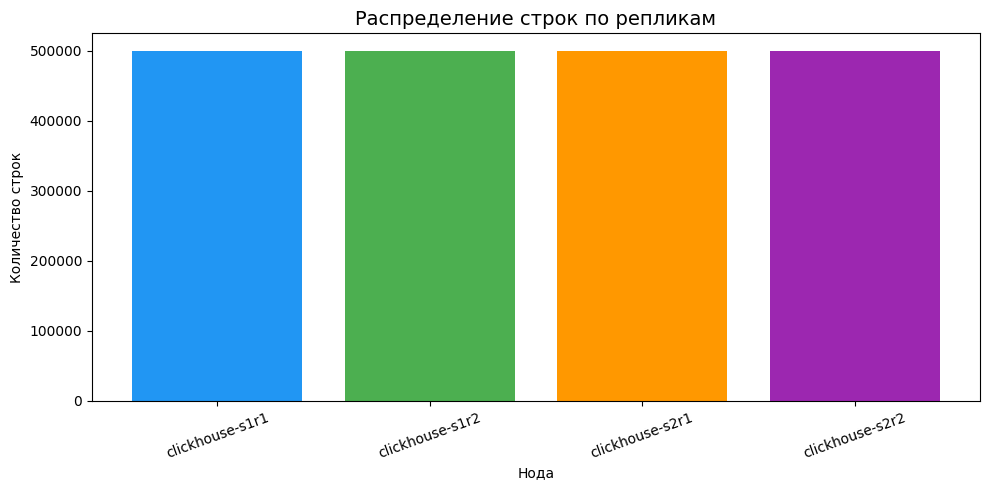

In [19]:
# Визуализируем распределение
df_vis = client.query_df("""
SELECT
    hostName()  AS host,
    sum(rows)   AS total_rows
FROM clusterAllReplicas('dwh_cluster', system.parts)
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
GROUP BY host
ORDER BY host
""")

plt.figure(figsize=(10, 5))
plt.bar(df_vis['host'], df_vis['total_rows'], color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'])
plt.title('Распределение строк по репликам', fontsize=14)
plt.xlabel('Нода')
plt.ylabel('Количество строк')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [51]:
df = client.query_df("""
SELECT count(*) from dwh.events_local
""")
print(df.to_string(index=False))

 count()
  549955


In [52]:
df = client.query_df("""
SELECT count(*) from dwh.events
""")
print(df.to_string(index=False))

 count()
 1100000


In [36]:
df = client.query_df("""
SELECT count(*) from clusterAllReplicas('dwh_cluster', 'dwh.events_local')
""")
print(df.to_string(index=False))

 count()
 2200000


## 4. Исследуем MergeTree — Parts и сжатие

In [20]:
# Смотрим Parts — куски данных на диске
df = client.query_df("""
SELECT
    name                                            AS part_name,
    partition,
    rows,
    formatReadableSize(bytes_on_disk)               AS size,
    formatReadableSize(data_uncompressed_bytes)     AS uncompressed,
    round(data_uncompressed_bytes /
          data_compressed_bytes, 2)                AS compression_ratio,
    level,
    modification_time
FROM system.parts
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
ORDER BY modification_time DESC
LIMIT 20
""")
print("Parts на текущей ноде:")
print(df.to_string(index=False))

Parts на текущей ноде:
   part_name partition   rows     size uncompressed  compression_ratio  level   modification_time
202401_0_0_0    202401 171953 3.47 MiB     6.03 MiB               1.74      0 2026-07-08 20:56:03
202402_0_0_0    202402 161190 3.26 MiB     5.66 MiB               1.74      0 2026-07-08 20:56:03
202403_0_0_0    202403 166887 3.37 MiB     5.86 MiB               1.74      0 2026-07-08 20:56:03


In [21]:
# Сжатие по колонкам — кто сжимается лучше всего?
df = client.query_df("""
SELECT
    column,
    formatReadableSize(sum(data_compressed_bytes))      AS compressed,
    formatReadableSize(sum(data_uncompressed_bytes))    AS uncompressed,
    round(sum(data_uncompressed_bytes) /
          sum(data_compressed_bytes), 2)               AS compression_ratio
FROM system.parts_columns
WHERE active
  AND database = 'dwh'
  AND table = 'events_local'
GROUP BY column
ORDER BY compression_ratio DESC
""")
print("Сжатие по колонкам:")
print(df.to_string(index=False))

Сжатие по колонкам:
    column compressed uncompressed  compression_ratio
   user_id  10.10 MiB    17.55 MiB               1.74
     value  10.10 MiB    17.55 MiB               1.74
  platform  10.10 MiB    17.55 MiB               1.74
   country  10.10 MiB    17.55 MiB               1.74
session_id  10.10 MiB    17.55 MiB               1.74
event_time  10.10 MiB    17.55 MiB               1.74
event_type  10.10 MiB    17.55 MiB               1.74
event_date  10.10 MiB    17.55 MiB               1.74


In [53]:
# Ждём пока CH сделает merge (объединит мелкие Parts)
print("Ждём merge...")
time.sleep(10)

# Смотрим активные merge
df = client.query_df("""
SELECT
    hostName()                          AS host,
    database,
    table,
    elapsed,
    round(progress * 100, 1)            AS progress_pct,
    formatReadableSize(total_size_bytes_compressed) AS size
FROM clusterAllReplicas('dwh_cluster', system.merges)
""")
if len(df) > 0:
    print("Активные merge:")
    print(df.to_string(index=False))
else:
    print("Merge завершены")

Ждём merge...
Активные merge:
           host database     table  elapsed  progress_pct     size
clickhouse-s2r2   system trace_log 0.216393          99.8 2.27 MiB


## 5. Аналитические запросы

Смотрим насколько быстро ClickHouse обрабатывает аналитику

In [54]:
# Запрос 1: события по типу
start = time.time()
df = client.query_df("""
SELECT
    event_type,
    count()             AS events,
    uniq(user_id)       AS unique_users,
    round(avg(value), 2) AS avg_value,
    round(sum(value), 2) AS total_value
FROM dwh.events
GROUP BY event_type
ORDER BY events DESC
""")
elapsed = time.time() - start
print(f"Запрос выполнен за {elapsed:.3f} сек на {df['events'].sum():,} строках")
print(df.to_string(index=False))

Запрос выполнен за 0.391 сек на 1,100,000 строках
 event_type  events  unique_users  avg_value  total_value
     search  183968         84259     498.96  91792798.99
      click  183573         84262     499.35  91666932.21
     logout  183313         84043     500.20  91692826.43
       view  183169         84156     499.32  91460367.37
   purchase  183092         84321     499.78  91504864.66
add_to_cart  182885         84237     499.73  91393659.87


Запрос выполнен за 0.096 сек


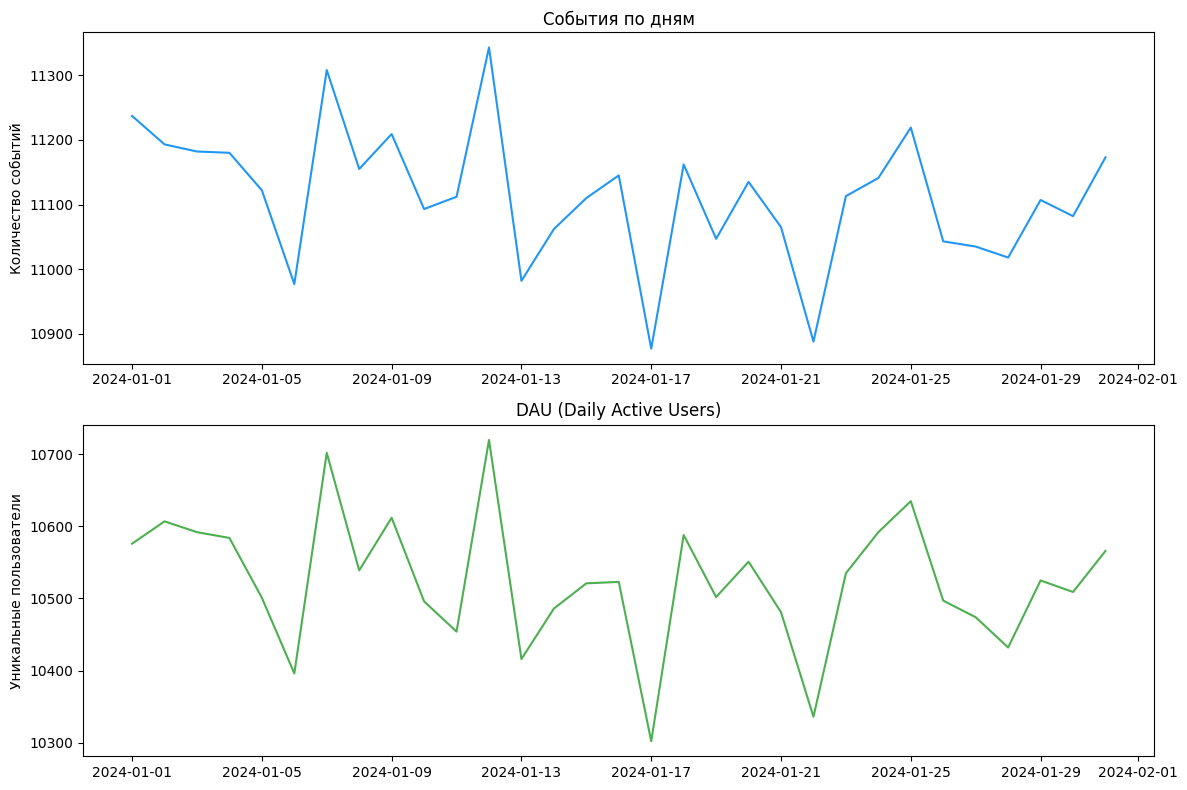

In [55]:
# Запрос 2: динамика по дням
start = time.time()
df = client.query_df("""
SELECT
    event_date,
    count()         AS events,
    uniq(user_id)   AS dau
FROM dwh.events
WHERE event_date BETWEEN '2024-01-01' AND '2024-01-31'
GROUP BY event_date
ORDER BY event_date
""")
elapsed = time.time() - start
print(f"Запрос выполнен за {elapsed:.3f} сек")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
ax1.plot(df['event_date'], df['events'], color='#2196F3')
ax1.set_title('События по дням')
ax1.set_ylabel('Количество событий')

ax2.plot(df['event_date'], df['dau'], color='#4CAF50')
ax2.set_title('DAU (Daily Active Users)')
ax2.set_ylabel('Уникальные пользователи')

plt.tight_layout()
plt.show()

In [56]:
# Запрос 3: воронка событий
df = client.query_df("""
SELECT
    platform,
    country,
    countIf(event_type = 'view')        AS views,
    countIf(event_type = 'click')       AS clicks,
    countIf(event_type = 'add_to_cart') AS add_to_cart,
    countIf(event_type = 'purchase')    AS purchases,
    round(countIf(event_type = 'purchase') /
          countIf(event_type = 'view') * 100, 2) AS conversion_pct
FROM dwh.events
GROUP BY platform, country
ORDER BY conversion_pct DESC
LIMIT 15
""")
print("Воронка по платформе и стране:")
print(df.to_string(index=False))

Воронка по платформе и стране:
platform country  views  clicks  add_to_cart  purchases  conversion_pct
 android      CN   8627    8744         8746       8865          102.76
 android      RU   8604    8810         8667       8780          102.05
     web      US   8717    8643         8673       8813          101.10
 android      IN   8716    8561         8775       8810          101.08
     web      BR   8697    8766         8716       8779          100.94
     ios      DE   8696    8582         8845       8744          100.55
     ios      FR   8728    8582         8661       8768          100.46
 android      FR   8799    8569         8641       8835          100.41
     web      CN   8667    8772         8640       8692          100.29
     web      FR   8687    8853         8662       8711          100.28
     ios      RU   8605    8953         8719       8624          100.22
     ios      US   8684    8699         8962       8694          100.12
 android      DE   8681    8802  

## 6. Partition pruning — как CH пропускает ненужные данные

In [26]:
# Без фильтра по дате — читаем все партиции
result = client.query("""
SELECT count()
FROM dwh.events
SETTINGS send_progress_in_http_headers = 1
""")

# С фильтром по дате — читаем только нужную партицию
# Смотрим через query_log сколько данных было прочитано
client.command("SYSTEM FLUSH LOGS")

df = client.query_df("""
SELECT
    query,
    read_rows,
    read_bytes,
    formatReadableSize(read_bytes)  AS read_size,
    query_duration_ms               AS duration_ms
FROM system.query_log
WHERE type = 'QueryFinish'
  AND query LIKE '%dwh.events%'
  AND event_time > now() - INTERVAL 5 MINUTE
ORDER BY event_time DESC
LIMIT 5
""")
print("Последние запросы к events:")
print(df[['read_rows', 'read_size', 'duration_ms']].to_string(index=False))

Последние запросы к events:
 read_rows read_size  duration_ms
         2   32.00 B           10
   1000000  2.86 MiB           55
    344515  3.29 MiB          109
   1000000 16.21 MiB          115
   1000000 42.70 MiB         2130


## 7. MaterializedView — агрегация в реальном времени

In [59]:
# Создаём таблицу для агрегатов
client.command("""
CREATE TABLE IF NOT EXISTS dwh.events_hourly_local ON CLUSTER dwh_cluster
(
    hour            DateTime,
    event_type      LowCardinality(String),
    platform        LowCardinality(String),
    events_count    UInt64,
    unique_users    AggregateFunction(uniq, UInt64),
    total_value     Float64
)
ENGINE = ReplicatedAggregatingMergeTree(
    '/clickhouse/tables/{shard}/dwh/events_hourly_local',
    '{replica}'
)
PARTITION BY toYYYYMM(hour)
ORDER BY (hour, event_type, platform)
""")

client.command("""
CREATE TABLE IF NOT EXISTS dwh.events_hourly ON CLUSTER dwh_cluster
AS dwh.events_hourly_local
ENGINE = Distributed('dwh_cluster', 'dwh', 'events_hourly_local', rand())
""")

print("Таблица events_hourly создана")

Таблица events_hourly создана


In [58]:
# Создаём MaterializedView — будет срабатывать при каждом INSERT в events_local
client.command("""
CREATE MATERIALIZED VIEW IF NOT EXISTS dwh.events_hourly_mv ON CLUSTER dwh_cluster
TO dwh.events_hourly_local
AS SELECT
    toStartOfHour(event_time)   AS hour,
    event_type,
    platform,
    count()                     AS events_count,
    uniqState(user_id)          AS unique_users,
    sum(value)                  AS total_value
FROM dwh.events_local
GROUP BY hour, event_type, platform
""")
print("MaterializedView events_hourly_mv создан")

MaterializedView events_hourly_mv создан


In [60]:
# Вставляем новые данные — MV сработает автоматически
new_rows = []
base_date = datetime(2024, 4, 1)
for i in range(100_000):
    event_time = base_date + timedelta(
        hours=random.randint(0, 23),
        minutes=random.randint(0, 59)
    )
    new_rows.append((
        event_time.date(), event_time,
        random.randint(1, 100_000),
        random.choice(event_types),
        random.choice(platforms),
        random.choice(countries),
        round(random.uniform(0, 1000), 2),
        f'sess_{random.randint(1, 500_000)}'
    ))

client.insert('dwh.events', new_rows,
    column_names=['event_date', 'event_time', 'user_id', 'event_type',
                  'platform', 'country', 'value', 'session_id'])
print(f"Вставлено {len(new_rows):,} новых строк")

Вставлено 100,000 новых строк


In [61]:
# Запрашиваем агрегаты — мгновенно, данные уже посчитаны
start = time.time()
df = client.query_df("""
SELECT
    hour,
    event_type,
    platform,
    sum(events_count)               AS events,
    uniqMerge(unique_users)         AS unique_users,
    round(sum(total_value), 2)      AS total_value
FROM dwh.events_hourly
WHERE hour >= '2024-04-01'
GROUP BY hour, event_type, platform
ORDER BY hour, events DESC
LIMIT 20
""")
elapsed = time.time() - start
print(f"Агрегаты получены за {elapsed:.3f} сек (данные уже посчитаны MV)")
print(df.to_string(index=False))

Агрегаты получены за 0.093 сек (данные уже посчитаны MV)
               hour  event_type platform  events  unique_users  total_value
2024-04-01 00:00:00    purchase      web     507           505    245247.08
2024-04-01 00:00:00      search      ios     507           506    240730.79
2024-04-01 00:00:00 add_to_cart      web     494           494    242546.61
2024-04-01 00:00:00      logout      web     485           482    244981.71
2024-04-01 00:00:00       click      ios     479           478    237584.43
2024-04-01 00:00:00      logout      ios     472           468    229412.25
2024-04-01 00:00:00 add_to_cart      ios     472           470    237751.57
2024-04-01 00:00:00      logout  android     472           470    234426.49
2024-04-01 00:00:00        view      ios     470           469    234514.67
2024-04-01 00:00:00        view  android     469           468    234479.11
2024-04-01 00:00:00    purchase      ios     464           463    232299.33
2024-04-01 00:00:00       click

## 8. Мониторинг кластера через system таблицы

In [31]:
# Распределение данных по шардам
df = client.query_df("""
SELECT
    hostName()                              AS host,
    count()                                 AS parts,
    formatReadableQuantity(sum(rows))       AS rows,
    formatReadableSize(sum(bytes_on_disk))  AS size
FROM clusterAllReplicas('dwh_cluster', system.parts)
WHERE active AND database = 'dwh'
GROUP BY host
ORDER BY host
""")
print("Распределение данных по кластеру:")
print(df.to_string(index=False))

Распределение данных по кластеру:
           host  parts            rows      size
clickhouse-s1r1      6 550.39 thousand 11.21 MiB
clickhouse-s1r2      6 550.39 thousand 11.21 MiB
clickhouse-s2r1      6 550.48 thousand 11.21 MiB
clickhouse-s2r2      6 550.48 thousand 11.21 MiB


In [32]:
# Состояние репликации
df = client.query_df("""
SELECT
    hostName()          AS host,
    database,
    table,
    is_leader,
    is_readonly,
    total_replicas,
    active_replicas,
    queue_size
FROM clusterAllReplicas('dwh_cluster', system.replicas)
WHERE database = 'dwh'
ORDER BY host, table
""")
print("Состояние репликации:")
print(df.to_string(index=False))

Состояние репликации:
           host database               table  is_leader  is_readonly  total_replicas  active_replicas  queue_size
clickhouse-s1r1      dwh events_hourly_local          1            0               2                2           0
clickhouse-s1r1      dwh        events_local          1            0               2                2           0
clickhouse-s1r2      dwh events_hourly_local          1            0               2                2           0
clickhouse-s1r2      dwh        events_local          1            0               2                2           0
clickhouse-s2r1      dwh events_hourly_local          1            0               2                2           0
clickhouse-s2r1      dwh        events_local          1            0               2                2           0
clickhouse-s2r2      dwh events_hourly_local          1            0               2                2           0
clickhouse-s2r2      dwh        events_local          1           

In [33]:
# Метрики фоновых пулов
df = client.query_df("""
SELECT
    hostName()  AS host,
    metric,
    value
FROM clusterAllReplicas('dwh_cluster', system.metrics)
WHERE metric LIKE '%Background%'
ORDER BY host, metric
""")
print("Фоновые пулы:")
print(df.to_string(index=False))

Фоновые пулы:
           host                                      metric  value
clickhouse-s1r1       BackgroundBufferFlushSchedulePoolSize     16
clickhouse-s1r1       BackgroundBufferFlushSchedulePoolTask      0
clickhouse-s1r1                    BackgroundCommonPoolSize     16
clickhouse-s1r1                    BackgroundCommonPoolTask      0
clickhouse-s1r1       BackgroundDistributedSchedulePoolSize     16
clickhouse-s1r1       BackgroundDistributedSchedulePoolTask      0
clickhouse-s1r1                   BackgroundFetchesPoolSize     32
clickhouse-s1r1                   BackgroundFetchesPoolTask      0
clickhouse-s1r1        BackgroundMergesAndMutationsPoolSize     64
clickhouse-s1r1        BackgroundMergesAndMutationsPoolTask      0
clickhouse-s1r1     BackgroundMessageBrokerSchedulePoolSize     16
clickhouse-s1r1     BackgroundMessageBrokerSchedulePoolTask      0
clickhouse-s1r1                      BackgroundMovePoolSize     16
clickhouse-s1r1                      BackgroundM